# 02 — Ordered session funnel

Synthetic data only. Seed 42; session-level analysis. Ground truth is reserved for evaluation.

## Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

## Config

In [2]:
ROOT = Path.cwd() if (Path.cwd() / 'requirements.txt').exists() else Path.cwd().parent
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
ALPHA, POWER = 0.05, 0.80
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
pd.set_option('display.max_columns', 50)

## Data Cleaning and Preprocessing

In [3]:
events = pd.read_csv(RAW / 'events.csv')
sessions = pd.read_csv(RAW / 'sessions.csv')

In [4]:
for name, df in [('events', events), ('sessions', sessions)]:
    print(f'{name}: Total Rows: {len(df):,}; Total Columns: {df.shape[1]}')
    display(df.isna().sum().rename('null_count').to_frame())

events: Total Rows: 212,476; Total Columns: 14


,null_count
event_id,0
user_id,0
session_id,0
event_timestamp,0
event_name,0
page_name,0
product_id,131791
click_count,0
duration_seconds,89320
error_type,207395


sessions: Total Rows: 20,000; Total Columns: 12


,null_count
session_id,0
user_id,0
scenario,0
ground_truth_friction,0
ground_truth_suspicious,0
purchased,0
reached_cart,0
reached_checkout,0
device_type,0
acquisition_channel,0


Optional product, duration, error, payment and navigation telemetry is structurally missing. Preserve it. Required identifiers/timestamps must be complete; fail instead of silently dropping records. No `dropna` is justified on these files.

In [5]:
assert events[['event_id', 'user_id', 'session_id', 'event_timestamp', 'event_name']].notna().all().all()
assert sessions[['session_id', 'user_id']].notna().all().all()
for name, df, key in [('events', events, 'event_id'), ('sessions', sessions, 'session_id')]:
    print(f'{name}: Duplicate rows: {df.duplicated().sum()}; Duplicate IDs: {df[key].duplicated().sum()}')
    duplicates = df[df.duplicated(key, keep=False)]
    assert not duplicates.drop_duplicates().duplicated(key).any(), 'Conflicting duplicate IDs require review'

events: Duplicate rows: 0; Duplicate IDs: 0


sessions: Duplicate rows: 0; Duplicate IDs: 0


Only exact repeats of an ID may be deduplicated, after confirming they agree. Distinct events, including repeated clicks and tied timestamps, remain valid.

In [6]:
events = events.drop_duplicates('event_id').copy()
sessions = sessions.drop_duplicates('session_id').copy()
events['event_timestamp'] = pd.to_datetime(events['event_timestamp'], errors='coerce')
assert events.event_timestamp.notna().all(), 'Invalid timestamps'

In [7]:
for df in [events, sessions]:
    df.info()
    display(df.describe(include='number'))

<class 'pandas.DataFrame'>
RangeIndex: 212476 entries, 0 to 212475
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   event_id             212476 non-null  str           
 1   user_id              212476 non-null  str           
 2   session_id           212476 non-null  str           
 3   event_timestamp      212476 non-null  datetime64[us]
 4   event_name           212476 non-null  str           
 5   page_name            212476 non-null  str           
 6   product_id           80685 non-null   str           
 7   click_count          212476 non-null  int64         
 8   duration_seconds     123156 non-null  float64       
 9   error_type           5081 non-null    str           
 10  payment_status       20817 non-null   str           
 11  navigation_action    4048 non-null    str           
 12  device_type          212476 non-null  str           
 13  acquisition_channel  2124

,click_count,duration_seconds
count,212476.000000,123156.000000
mean,0.346924,17.225050
std,1.184701,13.632646
min,0.000000,0.100011
25%,0.000000,8.633295
50%,0.000000,13.943835
75%,0.000000,22.070250
max,8.000000,307.097127


<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   session_id                20000 non-null  str    
 1   user_id                   20000 non-null  str    
 2   scenario                  20000 non-null  str    
 3   ground_truth_friction     20000 non-null  int64  
 4   ground_truth_suspicious   20000 non-null  int64  
 5   purchased                 20000 non-null  int64  
 6   reached_cart              20000 non-null  int64  
 7   reached_checkout          20000 non-null  int64  
 8   device_type               20000 non-null  str    
 9   acquisition_channel       20000 non-null  str    
 10  session_duration_seconds  20000 non-null  float64
 11  event_count               20000 non-null  int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 2.6 MB


,ground_truth_friction,ground_truth_suspicious,purchased,reached_cart,reached_checkout,session_duration_seconds,event_count
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,0.216100,0.069250,0.208800,0.820600,0.368650,78.149643,10.623800
std,0.411594,0.253885,0.406461,0.383696,0.482451,36.289687,5.664634
min,0.000000,0.000000,0.000000,0.000000,0.000000,3.400000,3.000000
25%,0.000000,0.000000,0.000000,1.000000,0.000000,53.020000,7.000000
50%,0.000000,0.000000,0.000000,1.000000,0.000000,74.340000,9.000000
75%,0.000000,0.000000,0.000000,1.000000,1.000000,99.945000,12.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,258.600000,40.000000


In [8]:
allowed = {'session_start', 'homepage_view', 'search', 'product_view', 'add_to_cart',
           'cart_view', 'remove_from_cart', 'checkout_start', 'payment_attempt', 'purchase',
           'click', 'back_navigation', 'page_error', 'payment_failure', 'payment_success', 'session_exit'}
assert set(events.event_name) <= allowed
assert (events.duration_seconds.dropna() >= 0).all() and (events.click_count >= 0).all()
assert set(events.session_id) == set(sessions.session_id)
assert events.groupby('session_id').event_timestamp.apply(lambda x: x.is_monotonic_increasing).all()
context = events.merge(sessions[['session_id', 'user_id', 'device_type', 'acquisition_channel']],
                       on='session_id', suffixes=('', '_session'), validate='many_to_one')
for col in ['user_id', 'device_type', 'acquisition_channel']:
    assert context[col].eq(context[col + '_session']).all()
print('Required values, timestamps, nonnegative telemetry, event types and context: passed')

Required values, timestamps, nonnegative telemetry, event types and context: passed


In [9]:
events = events.sort_values(['session_id', 'event_timestamp'], kind='stable').reset_index(drop=True)
events['event_position'] = np.arange(len(events))
counts = pd.crosstab(events.session_id, events.event_name).reindex(sessions.session_id, fill_value=0)
elapsed = events.groupby('session_id').event_timestamp.agg(['min', 'max'])
elapsed['duration'] = (elapsed['max'] - elapsed['min']).dt.total_seconds()
audit = sessions.set_index('session_id')
assert counts.sum(axis=1).eq(audit.event_count).all()
for event, field in [('purchase', 'purchased'), ('add_to_cart', 'reached_cart'), ('checkout_start', 'reached_checkout')]:
    assert counts[event].gt(0).astype(int).eq(audit[field]).all()
timing_error = (elapsed.duration - audit.session_duration_seconds).abs()
assert timing_error.max() <= 1.01, 'Timestamp precision discrepancy exceeds one second'
assert counts.session_start.eq(1).all()
assert events.groupby('session_id').first().event_name.eq('session_start').all()
terminal = events.groupby('session_id').last().event_name
print('Sessions with final event other than purchase/exit:', int((~terminal.isin(['purchase', 'session_exit'])).sum()))
print('Purchase sessions without payment_attempt:', int((counts.purchase.gt(0) & counts.payment_attempt.eq(0)).sum()))
print(f'Maximum duration discrepancy: {timing_error.max():.2f} seconds (timestamp rounding)')
print(f'Repeated user IDs across sessions: {sessions.user_id.duplicated().sum():,}')

Sessions with final event other than purchase/exit: 1385
Purchase sessions without payment_attempt: 473
Maximum duration discrepancy: 0.95 seconds (timestamp rounding)
Repeated user IDs across sessions: 8,997


## Column Description

One line per loaded/derived column; identifiers are linkage fields and synthetic labels are evaluation metadata only.

In [10]:
for name, df in [('events', events), ('sessions', sessions)]:
    display(Markdown('### ' + name + '\n' + '\n'.join(f'- `{c}` [{df[c].dtype}]' for c in df.columns)))

### events
- `event_id` [str]
- `user_id` [str]
- `session_id` [str]
- `event_timestamp` [datetime64[us]]
- `event_name` [str]
- `page_name` [str]
- `product_id` [str]
- `click_count` [int64]
- `duration_seconds` [float64]
- `error_type` [str]
- `payment_status` [str]
- `navigation_action` [str]
- `device_type` [str]
- `acquisition_channel` [str]
- `event_position` [int64]

### sessions
- `session_id` [str]
- `user_id` [str]
- `scenario` [str]
- `ground_truth_friction` [int64]
- `ground_truth_suspicious` [int64]
- `purchased` [int64]
- `reached_cart` [int64]
- `reached_checkout` [int64]
- `device_type` [str]
- `acquisition_channel` [str]
- `session_duration_seconds` [float64]
- `event_count` [int64]

## EDA

In [11]:
display(counts[['product_view', 'add_to_cart', 'checkout_start', 'payment_attempt', 'purchase']].gt(0).sum().rename('unordered unique-session reach'))

event_name
product_view       18876
add_to_cart        16412
checkout_start      7373
payment_attempt     6627
purchase            4176
Name: unordered unique-session reach, dtype: int64

## Problem Statement

Locate the largest observed losses in a chronological funnel, counting each session once per stage.

## Numbered Questions

### 1. Where do sessions leave the ordered funnel?
Descriptive census of this synthetic dataset: no independent-group test is appropriate for nested funnel stages. No power calculation applies.

A session qualifies only if each required stage occurs after its preceding stage; equal timestamps retain supplied event-row order. Sessions missing an earlier stage cannot enter later stages. The initial denominator includes every session.

In [12]:
stages = ['product_view', 'add_to_cart', 'checkout_start', 'payment_attempt', 'purchase']
reached = pd.Series(-1, index=pd.Index(sessions.session_id, name='session_id'))
rows = [{'stage': 'all_sessions', 'sessions': len(reached)}]
for stage in stages:
    candidates = events.loc[events.event_name.eq(stage), ['session_id', 'event_position']].copy()
    candidates['previous_position'] = candidates.session_id.map(reached)
    valid = candidates[candidates.event_position.gt(candidates.previous_position)]
    reached = valid.groupby('session_id').event_position.min()
    rows.append({'stage': stage, 'sessions': len(reached)})
funnel = pd.DataFrame(rows)

In [13]:
funnel['previous_sessions'] = funnel.sessions.shift()
funnel['stage_conversion_pct'] = 100 * funnel.sessions / funnel.previous_sessions
funnel['dropoff_sessions'] = funnel.previous_sessions - funnel.sessions
funnel['dropoff_pct'] = 100 - funnel.stage_conversion_pct
funnel['overall_reach_pct'] = 100 * funnel.sessions / len(sessions)
assert funnel.sessions.is_monotonic_decreasing
assert funnel.sessions.iloc[-1] <= counts.purchase.gt(0).sum()
assert (funnel.dropoff_sessions.iloc[1:] + funnel.sessions.iloc[1:]).eq(funnel.previous_sessions.iloc[1:]).all()
display(funnel.round(2))
funnel.to_csv(PROCESSED / 'funnel_summary.csv', index=False)

,stage,sessions,previous_sessions,stage_conversion_pct,dropoff_sessions,dropoff_pct,overall_reach_pct
0,all_sessions,20000,NaN,NaN,NaN,NaN,100.00
1,product_view,18876,20000.0,94.38,1124.0,5.62,94.38
2,add_to_cart,16412,18876.0,86.95,2464.0,13.05,82.06
3,checkout_start,7373,16412.0,44.92,9039.0,55.08,36.86
4,payment_attempt,6627,7373.0,89.88,746.0,10.12,33.14
5,purchase,3703,6627.0,55.88,2924.0,44.12,18.52


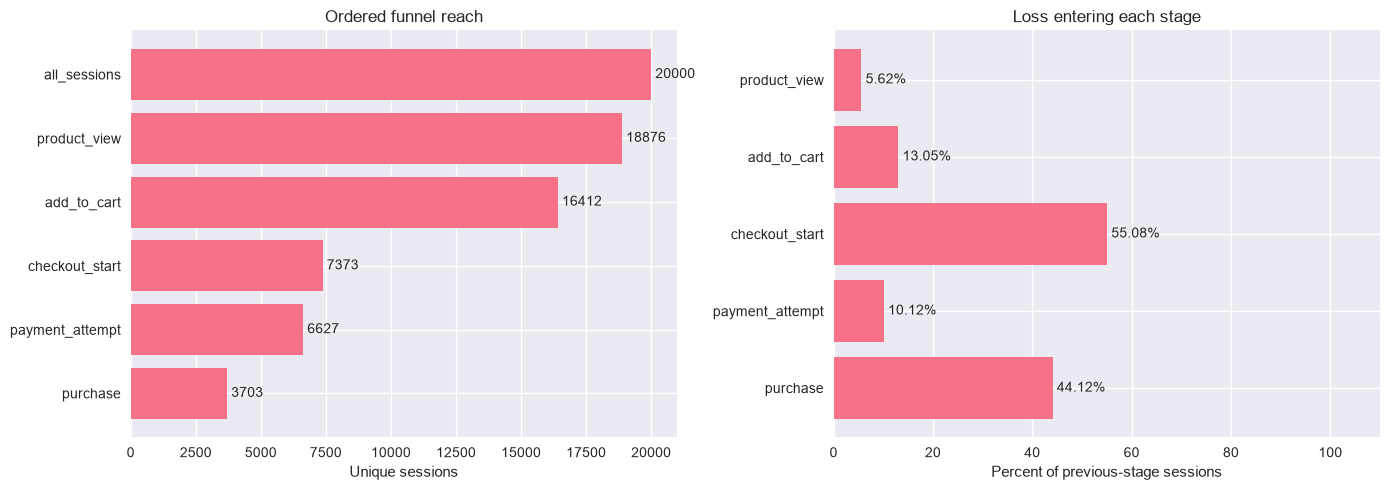

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(funnel.stage, funnel.sessions)
ax[0].invert_yaxis()
ax[0].bar_label(ax[0].containers[0], fmt='%.0f', padding=3)
ax[0].set(title='Ordered funnel reach', xlabel='Unique sessions')
ax[1].barh(funnel.stage.iloc[1:], funnel.dropoff_pct.iloc[1:])
ax[1].invert_yaxis()
ax[1].bar_label(ax[1].containers[0], labels=[f'{x:.2f}%' for x in funnel.dropoff_pct.iloc[1:]], padding=3)
ax[1].set(title='Loss entering each stage', xlabel='Percent of previous-stage sessions', xlim=(0, 110))
plt.tight_layout(); plt.show()

### 2. Which transition should be investigated first?
Descriptive prioritization by absolute loss and conditional loss percentage; no inferential test applies.

In [15]:
biggest = funnel.loc[funnel.dropoff_sessions.idxmax()]
relative = funnel.loc[funnel.dropoff_pct.idxmax()]
print(f'Largest absolute loss entering {biggest.stage}: {int(biggest.dropoff_sessions):,} sessions ({biggest.dropoff_pct:.2f}%)')
print(f'Largest relative loss entering {relative.stage}: {relative.dropoff_pct:.2f}%')
print(f'Ordered purchase conversion: {funnel.overall_reach_pct.iloc[-1]:.2f}%')
print(f'Observed purchase conversion (any purchase event): {counts.purchase.gt(0).mean():.2%}')
print('Purchase sessions excluded by strict ordering:', int(counts.purchase.gt(0).sum() - funnel.sessions.iloc[-1]))

Largest absolute loss entering checkout_start: 9,039 sessions (55.08%)
Largest relative loss entering checkout_start: 55.08%
Ordered purchase conversion: 18.52%
Observed purchase conversion (any purchase event): 20.88%
Purchase sessions excluded by strict ordering: 473


## Summary

Use the exported conversion table to prioritize the largest absolute and relative losses reported above. The first stage has no previous-stage conversion or drop-off, so these entries are intentionally blank.

In [16]:
display(Markdown(f'**Priority:** {int(biggest.dropoff_sessions):,} sessions are lost entering `{biggest.stage}` ({biggest.dropoff_pct:.2f}%). Observed purchases: {counts.purchase.gt(0).mean():.2%}; ordered completion: {funnel.overall_reach_pct.iloc[-1]:.2f}%.'))

**Priority:** 9,039 sessions are lost entering `checkout_start` (55.08%). Observed purchases: 20.88%; ordered completion: 18.52%.

## Insights

Investigate cart-to-checkout discoverability, costs and intent with additional instrumentation. Audit missing payment-attempt events: strict ordered purchases differ from observed purchases. Funnel abandonment alone does not demonstrate friction or causality. Ordered reach is a session metric, not an event-frequency metric or a cross-session customer journey.